# Section B — Task 1: Daily Order Analysis with NumPy

This program analyzes 30 days of food delivery order counts and revenue using NumPy.

It calculates:
- Total orders
- Total revenue
- Mean and standard deviation of daily orders
- Day index with the highest revenue
- Peak days where orders exceed mean + 1 standard deviation
- Total number and combined revenue of peak days
- Weekly order totals using a 5 × 6 matrix

In [2]:
# Import NumPy
import numpy as np

# ---------------------------------------------------------
# 1. Create 30 days of order count and revenue data
# ---------------------------------------------------------

# Set seed so that the same random values are generated every time
np.random.seed(42)

# Generate 30 daily order counts between 100 and 800
orders = np.random.randint(100, 801, 30)

# Generate 30 daily revenue values between 5000 and 50000
revenue = np.random.uniform(5000, 50000, 30)


# ---------------------------------------------------------
# 2. Calculate basic statistics
# ---------------------------------------------------------

# Calculate total orders
total_orders = np.sum(orders)

# Calculate total revenue
total_revenue = np.sum(revenue)

# Calculate mean of daily orders
mean_orders = np.mean(orders)

# Calculate standard deviation of daily orders
std_orders = np.std(orders)

# Find the day index having the highest revenue
highest_revenue_day = np.argmax(revenue)


# Print the results
print("Total Orders:", total_orders)
print("Total Revenue:", round(total_revenue, 2))
print("Mean Daily Orders:", round(mean_orders, 2))
print("Standard Deviation of Daily Orders:", round(std_orders, 2))
print("Day Index with Highest Revenue:", highest_revenue_day)


# ---------------------------------------------------------
# 3. Find peak days using Boolean indexing
# Condition: orders > mean + 1 standard deviation
# ---------------------------------------------------------

# Calculate the peak-day threshold
peak_threshold = mean_orders + std_orders

# Create Boolean mask for peak days
peak_mask = orders > peak_threshold

# Select orders from peak days
peak_orders = orders[peak_mask]

# Select matching revenue from peak days
peak_revenue = revenue[peak_mask]

# Count the number of peak days
peak_day_count = np.sum(peak_mask)

# Calculate combined revenue of peak days
peak_total_revenue = np.sum(peak_revenue)


# Print peak-day results
print("\nPeak Day Threshold:", round(peak_threshold, 2))
print("Number of Peak Days:", peak_day_count)
print("Total Revenue of Peak Days:", round(peak_total_revenue, 2))


# ---------------------------------------------------------
# 4. Reshape orders into a 5 × 6 matrix
# Each row represents a block of 6 days
# ---------------------------------------------------------

orders_matrix = orders.reshape(5, 6)

# Calculate total orders for each row using axis=1
weekly_totals = np.sum(orders_matrix, axis=1)


# Print the matrix and weekly totals
print("\n5 × 6 Order Matrix:")
print(orders_matrix)

print("\nOrder Totals for Each of the 5 Weekly Blocks:")
print(weekly_totals)

Total Orders: 12279
Total Revenue: 743362.93
Mean Daily Orders: 409.3
Standard Deviation of Daily Orders: 195.9
Day Index with Highest Revenue: 10

Peak Day Threshold: 605.2
Number of Peak Days: 4
Total Revenue of Peak Days: 127639.11

5 × 6 Order Matrix:
[[202 535 370 206 171 800]
 [120 714 221 566 314 430]
 [558 187 472 199 763 230]
 [761 408 443 591 513 485]
 [291 376 260 559 413 121]]

Order Totals for Each of the 5 Weekly Blocks:
[2284 2365 2409 3201 2020]


# Section B — Task 2: Food Delivery Orders Data Cleaning Pipeline

This task creates a simulated food delivery orders dataset and performs data cleaning.

The pipeline includes:
- Creating at least 20 rows
- Introducing missing values
- Introducing duplicate rows
- Filling missing values using median, mean, and mode
- Removing duplicate rows
- Detecting outliers using IQR
- Capping outliers using `clip()`

In [3]:
# Import required libraries
import pandas as pd
import numpy as np

In [4]:
# Create a simulated food delivery dataset with 20 rows

data = {
    'order_id': range(1001, 1021),

    'customer_name': [
        'Rahul', 'Amit', 'Priya', 'Neha', 'Rohan',
        'Karan', 'Anjali', 'Vikas', 'Pooja', 'Arjun',
        'Mehul', 'Sneha', 'Yash', 'Riya', 'Akash',
        'Nisha', 'Jay', 'Kavya', 'Dev', 'Isha'
    ],

    'restaurant_name': [
        'Spice Hub', 'Pizza House', 'China Bowl', 'Food Corner',
        'Royal Dine', 'Spice Hub', 'Pizza House', 'Burger Point',
        'China Bowl', 'Royal Dine', 'Spice Hub', 'Pizza House',
        'Food Corner', 'Burger Point', 'China Bowl', 'Royal Dine',
        'Spice Hub', 'Pizza House', 'Food Corner', 'Burger Point'
    ],

    'category': [
        'Indian', 'Italian', 'Chinese', 'Fast Food', 'Indian',
        'Indian', 'Italian', 'Fast Food', 'Chinese', 'Indian',
        'Indian', 'Italian', 'Fast Food', 'Fast Food', 'Chinese',
        'Indian', 'Indian', 'Italian', 'Fast Food', 'Fast Food'
    ],

    'delivery_time_mins': [
        30, 40, 35, 25, 45,
        32, 38, 28, 42, 36,
        31, 44, 27, 33, 41,
        39, 29, 46, 34, 37
    ],

    'order_value': [
        350, 500, 450, 300, 700,
        400, 550, 250, 600, 480,
        320, 520, 280, 390, 650,
        750, 360, 580, 310, 430
    ],

    'rating': [
        4.5, 4.0, 3.8, 4.2, 4.7,
        4.1, 3.9, 4.3, 4.0, 4.6,
        4.4, 3.7, 4.2, 4.1, 3.9,
        4.8, 4.3, 4.0, 4.5, 4.2
    ]
}

df = pd.DataFrame(data)

# Display the original dataset
df

,order_id,customer_name,restaurant_name,category,delivery_time_mins,order_value,rating
0,1001,Rahul,Spice Hub,Indian,30,350,4.5
1,1002,Amit,Pizza House,Italian,40,500,4.0
2,1003,Priya,China Bowl,Chinese,35,450,3.8
3,1004,Neha,Food Corner,Fast Food,25,300,4.2
4,1005,Rohan,Royal Dine,Indian,45,700,4.7
5,1006,Karan,Spice Hub,Indian,32,400,4.1
6,1007,Anjali,Pizza House,Italian,38,550,3.9
7,1008,Vikas,Burger Point,Fast Food,28,250,4.3
8,1009,Pooja,China Bowl,Chinese,42,600,4.0
9,1010,Arjun,Royal Dine,Indian,36,480,4.6


In [5]:
# Manually introduce at least 4 missing values
# Missing values are added across numeric and categorical columns

df.loc[2, 'delivery_time_mins'] = np.nan
df.loc[5, 'order_value'] = np.nan
df.loc[8, 'rating'] = np.nan
df.loc[11, 'category'] = np.nan

# Display the dataset with missing values
df

,order_id,customer_name,restaurant_name,category,delivery_time_mins,order_value,rating
0,1001,Rahul,Spice Hub,Indian,30.0,350.0,4.5
1,1002,Amit,Pizza House,Italian,40.0,500.0,4.0
2,1003,Priya,China Bowl,Chinese,NaN,450.0,3.8
3,1004,Neha,Food Corner,Fast Food,25.0,300.0,4.2
4,1005,Rohan,Royal Dine,Indian,45.0,700.0,4.7
5,1006,Karan,Spice Hub,Indian,32.0,NaN,4.1
6,1007,Anjali,Pizza House,Italian,38.0,550.0,3.9
7,1008,Vikas,Burger Point,Fast Food,28.0,250.0,4.3
8,1009,Pooja,China Bowl,Chinese,42.0,600.0,NaN
9,1010,Arjun,Royal Dine,Indian,36.0,480.0,4.6


In [6]:
# Manually add 3 duplicate rows

df = pd.concat([
    df,
    df.iloc[[0, 1, 2]]
], ignore_index=True)

# Display the shape after adding duplicates
print("Shape after adding duplicates:", df.shape)

Shape after adding duplicates: (23, 7)


In [7]:
# Count missing values before filling

print("Null values before filling:")
print(df.isnull().sum())

Null values before filling:
order_id              0
customer_name         0
restaurant_name       0
category              1
delivery_time_mins    2
order_value           1
rating                1
dtype: int64


In [8]:
# Fill missing delivery_time_mins with the column median
df['delivery_time_mins'] = df['delivery_time_mins'].fillna(
    df['delivery_time_mins'].median()
)

# Fill missing order_value with the column median
df['order_value'] = df['order_value'].fillna(
    df['order_value'].median()
)

# Fill missing rating with the column mean rounded to 1 decimal place
rating_mean = round(df['rating'].mean(), 1)

df['rating'] = df['rating'].fillna(rating_mean)

# Fill missing category with the column mode
category_mode = df['category'].mode()[0]

df['category'] = df['category'].fillna(category_mode)

# Display cleaned missing-value columns
print("Missing values after filling:")
print(df.isnull().sum())

Missing values after filling:
order_id              0
customer_name         0
restaurant_name       0
category              0
delivery_time_mins    0
order_value           0
rating                0
dtype: int64


In [9]:
# Print shape before removing duplicates
print("Shape before removing duplicates:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Print shape after removing duplicates
print("Shape after removing duplicates:", df.shape)

Shape before removing duplicates: (23, 7)
Shape after removing duplicates: (20, 7)


In [10]:
# Calculate Q1 (25th percentile)
Q1 = df['order_value'].quantile(0.25)

# Calculate Q3 (75th percentile)
Q3 = df['order_value'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 342.5
Q3: 557.5
IQR: 215.0
Lower limit: 20.0
Upper limit: 880.0


In [11]:
# Identify rows where order_value is outside the IQR limits

outliers = df[
    (df['order_value'] < lower_limit) |
    (df['order_value'] > upper_limit)
]

print("Outlier rows:")
print(outliers)


Outlier rows:
Empty DataFrame
Columns: [order_id, customer_name, restaurant_name, category, delivery_time_mins, order_value, rating]
Index: []


In [12]:
# Cap order_value at the calculated lower and upper limits
# Values below lower_limit become lower_limit
# Values above upper_limit become upper_limit

df['order_value'] = df['order_value'].clip(
    lower=lower_limit,
    upper=upper_limit
)

# Display the final cleaned dataset
df

,order_id,customer_name,restaurant_name,category,delivery_time_mins,order_value,rating
0,1001,Rahul,Spice Hub,Indian,30.0,350.0,4.5
1,1002,Amit,Pizza House,Italian,40.0,500.0,4.0
2,1003,Priya,China Bowl,Chinese,36.0,450.0,3.8
3,1004,Neha,Food Corner,Fast Food,25.0,300.0,4.2
4,1005,Rohan,Royal Dine,Indian,45.0,700.0,4.7
5,1006,Karan,Spice Hub,Indian,32.0,450.0,4.1
6,1007,Anjali,Pizza House,Italian,38.0,550.0,3.9
7,1008,Vikas,Burger Point,Fast Food,28.0,250.0,4.3
8,1009,Pooja,China Bowl,Chinese,42.0,600.0,4.2
9,1010,Arjun,Royal Dine,Indian,36.0,480.0,4.6


In [13]:
# Final data quality check

print("Final shape:", df.shape)

print("\nFinal missing values:")
print(df.isnull().sum())

print("\nFinal dataset:")
print(df)

Final shape: (20, 7)

Final missing values:
order_id              0
customer_name         0
restaurant_name       0
category              0
delivery_time_mins    0
order_value           0
rating                0
dtype: int64

Final dataset:
    order_id customer_name restaurant_name   category  delivery_time_mins  \
0       1001         Rahul       Spice Hub     Indian                30.0   
1       1002          Amit     Pizza House    Italian                40.0   
2       1003         Priya      China Bowl    Chinese                36.0   
3       1004          Neha     Food Corner  Fast Food                25.0   
4       1005         Rohan      Royal Dine     Indian                45.0   
5       1006         Karan       Spice Hub     Indian                32.0   
6       1007        Anjali     Pizza House    Italian                38.0   
7       1008         Vikas    Burger Point  Fast Food                28.0   
8       1009         Pooja      China Bowl    Chinese             

# Section B — Task 3: Food Delivery Visualisation Dashboard

This dashboard uses Matplotlib and Seaborn to create four visualizations in a single 2×2 figure:

1. Order count per restaurant category
2. Delivery time distribution by category
3. Average order value per restaurant
4. Correlation heatmap of all numeric columns

In [14]:
# Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns

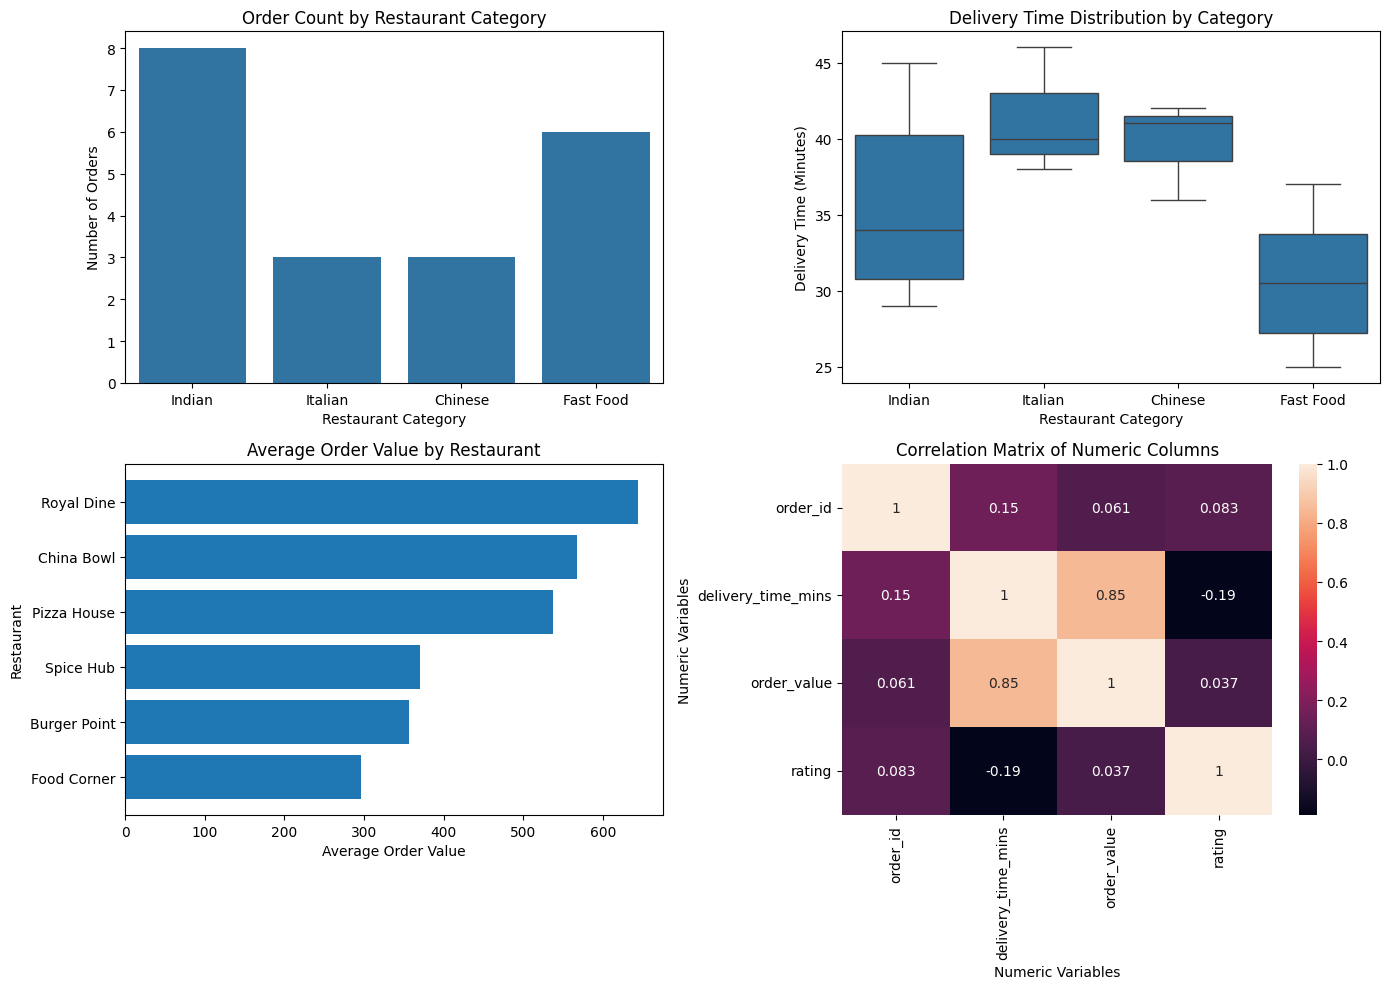

In [15]:
# Create a single figure with 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))


# ---------------------------------------------------------
# Plot 1: Order count per category
# Top-left
# ---------------------------------------------------------

sns.countplot(
    data=df,
    x='category',
    ax=axes[0, 0]
)

axes[0, 0].set_title('Order Count by Restaurant Category')
axes[0, 0].set_xlabel('Restaurant Category')
axes[0, 0].set_ylabel('Number of Orders')


# ---------------------------------------------------------
# Plot 2: Delivery time distribution by category
# Top-right
# ---------------------------------------------------------

sns.boxplot(
    data=df,
    x='category',
    y='delivery_time_mins',
    ax=axes[0, 1]
)

axes[0, 1].set_title('Delivery Time Distribution by Category')
axes[0, 1].set_xlabel('Restaurant Category')
axes[0, 1].set_ylabel('Delivery Time (Minutes)')


# ---------------------------------------------------------
# Plot 3: Average order value per restaurant
# Bottom-left
# ---------------------------------------------------------

# Calculate average order value for each restaurant
avg_order_value = (
    df.groupby('restaurant_name')['order_value']
    .mean()
    .sort_values()
)

# Create horizontal bar chart
axes[1, 0].barh(
    avg_order_value.index,
    avg_order_value.values
)

axes[1, 0].set_title('Average Order Value by Restaurant')
axes[1, 0].set_xlabel('Average Order Value')
axes[1, 0].set_ylabel('Restaurant')


# ---------------------------------------------------------
# Plot 4: Correlation heatmap
# Bottom-right
# ---------------------------------------------------------

# Select all numeric columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Create heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    ax=axes[1, 1]
)

axes[1, 1].set_title('Correlation Matrix of Numeric Columns')
axes[1, 1].set_xlabel('Numeric Variables')
axes[1, 1].set_ylabel('Numeric Variables')


# ---------------------------------------------------------
# Improve spacing between subplots
# ---------------------------------------------------------

plt.tight_layout()

# Display the dashboard
plt.show()

In [19]:
# Save the complete dashboard as a PNG file

plt.savefig(
    'food_delivery_dashboard.png',
    dpi=150,
    bbox_inches='tight'
)

print("Dashboard saved successfully as food_delivery_dashboard.png")

Dashboard saved successfully as food_delivery_dashboard.png


<Figure size 640x480 with 0 Axes>

# Section B — Task 4: SQL + Python Restaurant Performance Report

This task creates and populates a SQLite food delivery database using Python.

The program:
- Creates a SQLite database named `food_delivery.db`
- Creates `restaurants` and `orders` tables
- Inserts at least 8 restaurants and 25 orders
- Uses SQL GROUP BY with COUNT(), SUM(), and ROUND(AVG())
- Loads the SQL result into a Pandas DataFrame
- Ranks restaurants by total revenue
- Displays the Top 5 restaurants by revenue
- Exports the complete report to a CSV file

In [21]:
# Import SQLite for database operations
import sqlite3

# Import Pandas for data analysis
import pandas as pd

In [22]:
# Create/connect to the SQLite database
# The database file will be created in the current Jupyter folder

conn = sqlite3.connect('food_delivery.db')

# Create a cursor to execute SQL commands
cursor = conn.cursor()

# Create restaurants table
cursor.execute("""
CREATE TABLE IF NOT EXISTS restaurants (
    restaurant_id INTEGER PRIMARY KEY,
    name TEXT,
    category TEXT,
    city TEXT
)
""")

# Create orders table
cursor.execute("""
CREATE TABLE IF NOT EXISTS orders (
    order_id INTEGER PRIMARY KEY,
    restaurant_id INTEGER,
    order_value REAL,
    delivery_time_mins REAL,
    rating REAL
)
""")

print("Database and tables created successfully.")

Database and tables created successfully.


In [23]:
# Restaurant data
restaurants = [
    (1, 'Spice Hub', 'Indian', 'Surat'),
    (2, 'Pizza House', 'Italian', 'Surat'),
    (3, 'China Bowl', 'Chinese', 'Mumbai'),
    (4, 'Burger Point', 'Fast Food', 'Mumbai'),
    (5, 'Royal Dine', 'Indian', 'Ahmedabad'),
    (6, 'Pasta Corner', 'Italian', 'Ahmedabad'),
    (7, 'Food Junction', 'Fast Food', 'Surat'),
    (8, 'Tandoori Treat', 'Indian', 'Mumbai')
]

# Insert restaurants into the table
cursor.executemany("""
INSERT OR IGNORE INTO restaurants
(restaurant_id, name, category, city)
VALUES (?, ?, ?, ?)
""", restaurants)

# Save changes
conn.commit()

print("8 restaurants inserted successfully.")

8 restaurants inserted successfully.


In [24]:
# Create 25 orders
orders = [
    (101, 1, 450, 30, 4.5),
    (102, 1, 600, 35, 4.2),
    (103, 1, 550, 32, 4.6),
    (104, 1, 700, 40, 4.3),

    (105, 2, 800, 45, 4.1),
    (106, 2, 650, 42, 4.0),
    (107, 2, 900, 50, 4.4),

    (108, 3, 500, 35, 3.9),
    (109, 3, 450, 38, 4.0),
    (110, 3, 700, 40, 4.2),

    (111, 4, 300, 25, 3.8),
    (112, 4, 350, 28, 4.0),
    (113, 4, 400, 30, 3.7),

    (114, 5, 750, 40, 4.7),
    (115, 5, 850, 45, 4.6),
    (116, 5, 900, 48, 4.8),

    (117, 6, 600, 38, 4.2),
    (118, 6, 700, 42, 4.3),
    (119, 6, 550, 36, 4.0),

    (120, 7, 250, 25, 3.9),
    (121, 7, 300, 27, 4.1),
    (122, 7, 350, 29, 4.0),

    (123, 8, 800, 40, 4.5),
    (124, 8, 950, 45, 4.7),
    (125, 8, 700, 38, 4.4)
]

# Insert orders into the orders table
cursor.executemany("""
INSERT OR IGNORE INTO orders
(order_id, restaurant_id, order_value, delivery_time_mins, rating)
VALUES (?, ?, ?, ?, ?)
""", orders)

# Save changes
conn.commit()

print("25 orders inserted successfully.")

25 orders inserted successfully.


In [25]:
# SQL query to calculate restaurant performance
#
# COUNT()       -> total number of orders
# SUM()         -> total revenue
# ROUND(AVG())  -> average rating rounded to 2 decimals

sql_query = """
SELECT
    r.restaurant_id,
    r.name AS restaurant_name,
    r.category,
    r.city,
    COUNT(o.order_id) AS total_orders,
    COALESCE(SUM(o.order_value), 0) AS total_revenue,
    ROUND(AVG(o.rating), 2) AS avg_rating

FROM restaurants AS r

LEFT JOIN orders AS o
    ON r.restaurant_id = o.restaurant_id

GROUP BY
    r.restaurant_id,
    r.name,
    r.category,
    r.city

ORDER BY
    total_revenue DESC
"""

# Load SQL result into a Pandas DataFrame
df_report = pd.read_sql_query(sql_query, conn)

# Display the complete report
df_report

,restaurant_id,restaurant_name,category,city,total_orders,total_revenue,avg_rating
0,5,Royal Dine,Indian,Ahmedabad,3,2500.0,4.70
1,8,Tandoori Treat,Indian,Mumbai,3,2450.0,4.53
2,2,Pizza House,Italian,Surat,3,2350.0,4.17
3,1,Spice Hub,Indian,Surat,4,2300.0,4.40
4,6,Pasta Corner,Italian,Ahmedabad,3,1850.0,4.17
5,3,China Bowl,Chinese,Mumbai,3,1650.0,4.03
6,4,Burger Point,Fast Food,Mumbai,3,1050.0,3.83
7,7,Food Junction,Fast Food,Surat,3,900.0,4.00


In [26]:
# Add restaurant revenue rank
# Highest revenue gets rank 1

df_report['revenue_rank'] = (
    df_report['total_revenue']
    .rank(
        ascending=False,
        method='min'
    )
    .astype(int)
)

# Sort the report by revenue rank
df_report = df_report.sort_values(
    by='revenue_rank'
)

# Display the ranked report
df_report

,restaurant_id,restaurant_name,category,city,total_orders,total_revenue,avg_rating,revenue_rank
0,5,Royal Dine,Indian,Ahmedabad,3,2500.0,4.70,1
1,8,Tandoori Treat,Indian,Mumbai,3,2450.0,4.53,2
2,2,Pizza House,Italian,Surat,3,2350.0,4.17,3
3,1,Spice Hub,Indian,Surat,4,2300.0,4.40,4
4,6,Pasta Corner,Italian,Ahmedabad,3,1850.0,4.17,5
5,3,China Bowl,Chinese,Mumbai,3,1650.0,4.03,6
6,4,Burger Point,Fast Food,Mumbai,3,1050.0,3.83,7
7,7,Food Junction,Fast Food,Surat,3,900.0,4.00,8


In [27]:
# Select the Top 5 restaurants by total revenue

top_5 = df_report.head(5)

print("Top 5 Restaurants by Total Revenue")
print("=" * 60)

# Print the Top 5 in a formatted table
print(
    top_5[
        [
            'revenue_rank',
            'restaurant_name',
            'city',
            'total_orders',
            'total_revenue',
            'avg_rating'
        ]
    ].to_string(index=False)
)

Top 5 Restaurants by Total Revenue
 revenue_rank restaurant_name      city  total_orders  total_revenue  avg_rating
            1      Royal Dine Ahmedabad             3         2500.0        4.70
            2  Tandoori Treat    Mumbai             3         2450.0        4.53
            3     Pizza House     Surat             3         2350.0        4.17
            4       Spice Hub     Surat             4         2300.0        4.40
            5    Pasta Corner Ahmedabad             3         1850.0        4.17


In [28]:
# Export the complete restaurant performance report to CSV

output_file = 'restaurant_performance_report.csv'

df_report.to_csv(
    output_file,
    index=False
)

print("Complete report exported successfully.")
print("File name:", output_file)

Complete report exported successfully.
File name: restaurant_performance_report.csv


In [29]:
# Close the SQLite database connection

conn.close()

print("SQLite database connection closed.")

SQLite database connection closed.
